Starting Step 1: Loading and merging data...
Using Demographic file path: /DEMO_I.xpt
Using Body Measures file path: /BMX_I.xpt

=== STEP 1 SUMMARY: DATA VALIDATION & CLEANING ===
Counting missing (NaN) values per target column:
RIAGENDR      0
BMXHT       775
BMXWT        99
dtype: int64
Total raw records: 9544
Total clean & valid records remaining: 8756
Excluded 788 incomplete records.

Cleaned dataset sample (first 5 records):
 RIAGENDR  BMXHT  BMXWT Gender_Label
      1.0  184.5   94.8         Male
      1.0  171.4   90.4         Male
      1.0  170.1   83.4         Male
      2.0  160.9  109.8       Female
      2.0  164.9   55.2       Female

Starting Step 2: Generating detailed Frequency Histograms...
Plotting Height distributions...
Plotting Weight distributions...


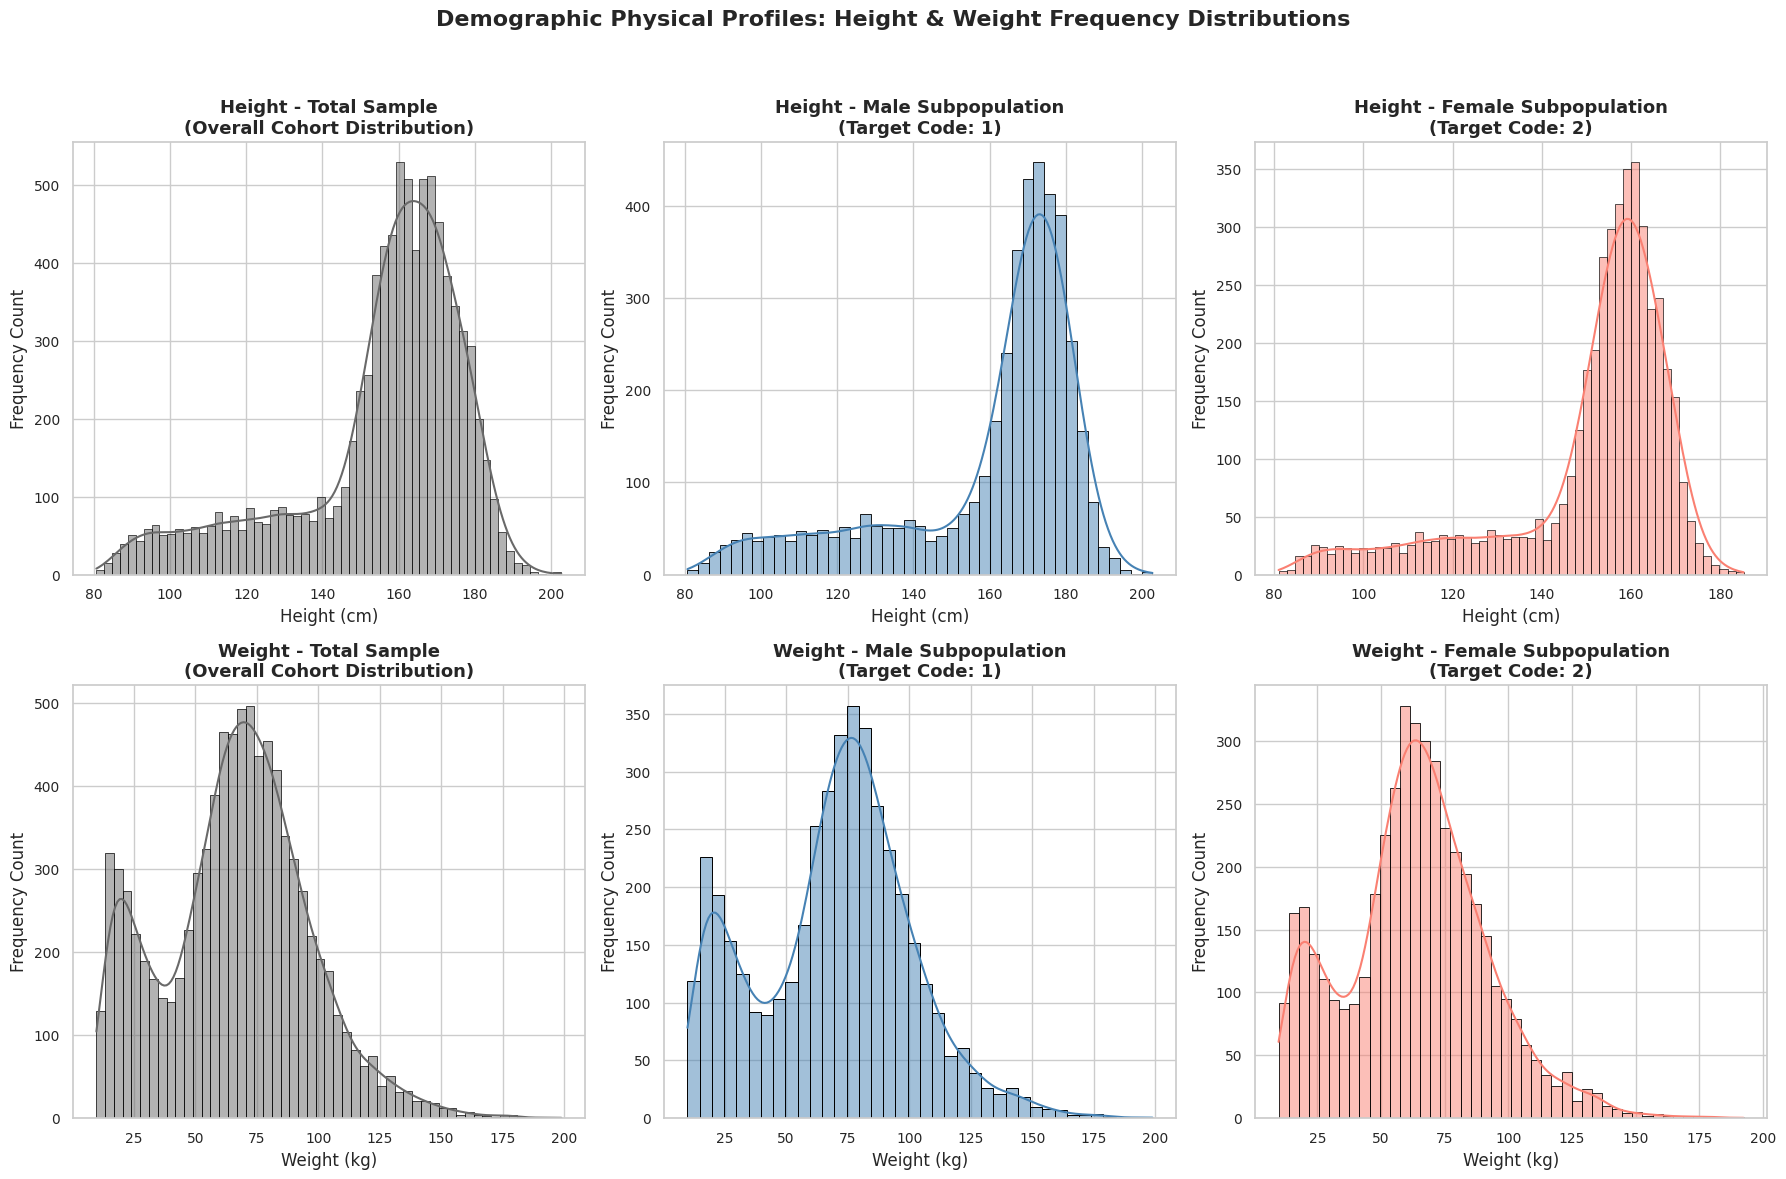


Starting Step 3: Computing descriptive statistics...

=== STEP 3: SUMMARY OF DESCRIPTIVE BIOMETRIC STATISTICS ===
        Cohort Biometric Variable  Sample Size (N)   Mean  Variance  Std Dev  Minimum  Q1 (25%)  Median (50%)  Q3 (75%)  Maximum
  Total Cohort        Height (cm)             8756 155.08    528.73    22.99     80.7    148.90         161.1     170.4    202.7
  Total Cohort        Weight (kg)             8756  66.60    891.95    29.87      9.8     47.80          68.1      85.2    198.9
  Male Segment        Height (cm)             4286 159.66    629.70    25.09     80.7    152.62         169.2     176.2    202.7
  Male Segment        Weight (kg)             4286  69.71    993.50    31.52      9.9     48.52          72.8      89.4    198.9
Female Segment        Height (cm)             4470 150.68    392.56    19.81     81.0    148.00         156.9     162.9    185.2
Female Segment        Weight (kg)             4470  63.63    776.68    27.87      9.8     47.32          63.8  

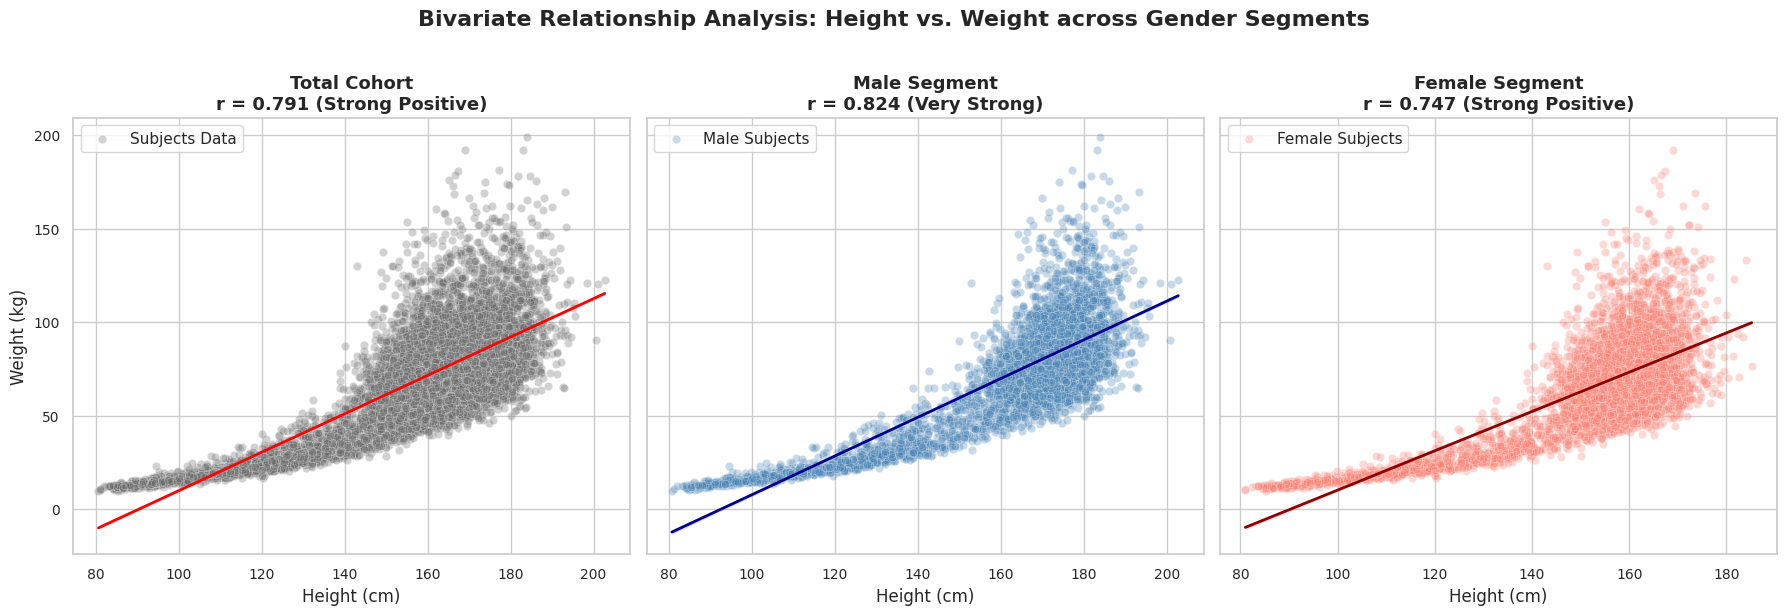


Execution finished successfully with all requested enhancements.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configure global plotting style for professional look
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10
})

# ==========================================
# STEP 1: Load, Extract, Merge and Clean Data
# ==========================================
print("Starting Step 1: Loading and merging data...")

# Identify correct paths for the dataset files
path_demo = 'DEMO_I.xpt' if os.path.exists('DEMO_I.xpt') else '/content/DEMO_I.xpt' if os.path.exists('/content/DEMO_I.xpt') else '/DEMO_I.xpt'
path_bmx = 'BMX_I.xpt' if os.path.exists('BMX_I.xpt') else '/content/BMX_I.xpt' if os.path.exists('/content/BMX_I.xpt') else '/BMX_I.xpt'

print(f"Using Demographic file path: {path_demo}")
print(f"Using Body Measures file path: {path_bmx}")

# Read SAS (.xpt) files
demo = pd.read_sas(path_demo, format='xport')
bmx = pd.read_sas(path_bmx, format='xport')

# Merge datasets on Subject ID (SEQN)
df = pd.merge(demo[['SEQN', 'RIAGENDR']], bmx[['SEQN', 'BMXHT', 'BMXWT']], on='SEQN')

# Select subset of interest and create explicit copy
df_sub = df[['RIAGENDR', 'BMXHT', 'BMXWT']].copy()

# Map gender numerical codes to string labels
df_sub['Gender_Label'] = df_sub['RIAGENDR'].map({1: 'Male', 2: 'Female'})

print("\n=== STEP 1 SUMMARY: DATA VALIDATION & CLEANING ===")
print("Counting missing (NaN) values per target column:")
print(df_sub[['RIAGENDR', 'BMXHT', 'BMXWT']].isna().sum())

# Drop rows containing missing values in key columns
df_clean = df_sub.dropna(subset=['BMXHT', 'BMXWT', 'RIAGENDR']).reset_index(drop=True)
print(f"Total raw records: {len(df_sub)}")
print(f"Total clean & valid records remaining: {len(df_clean)}")
print(f"Excluded {len(df_sub) - len(df_clean)} incomplete records.")

print("\nCleaned dataset sample (first 5 records):")
print(df_clean.head().to_string(index=False))

# ==========================================
# STEP 2: Frequency Histograms
# ==========================================
print("\nStarting Step 2: Generating detailed Frequency Histograms...")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Height Analysis (BMXHT)
print("Plotting Height distributions...")
sns.histplot(df_clean['BMXHT'], kde=True, ax=axes[0, 0], color='dimgray', edgecolor='black')
axes[0, 0].set_title('Height - Total Sample\n(Overall Cohort Distribution)', fontweight='bold')
axes[0, 0].set_xlabel('Height (cm)')
axes[0, 0].set_ylabel('Frequency Count')

sns.histplot(df_clean[df_clean['RIAGENDR']==1]['BMXHT'], kde=True, ax=axes[0, 1], color='steelblue', edgecolor='black')
axes[0, 1].set_title('Height - Male Subpopulation\n(Target Code: 1)', fontweight='bold')
axes[0, 1].set_xlabel('Height (cm)')
axes[0, 1].set_ylabel('Frequency Count')

sns.histplot(df_clean[df_clean['RIAGENDR']==2]['BMXHT'], kde=True, ax=axes[0, 2], color='salmon', edgecolor='black')
axes[0, 2].set_title('Height - Female Subpopulation\n(Target Code: 2)', fontweight='bold')
axes[0, 2].set_xlabel('Height (cm)')
axes[0, 2].set_ylabel('Frequency Count')

# 2. Weight Analysis (BMXWT)
print("Plotting Weight distributions...")
sns.histplot(df_clean['BMXWT'], kde=True, ax=axes[1, 0], color='dimgray', edgecolor='black')
axes[1, 0].set_title('Weight - Total Sample\n(Overall Cohort Distribution)', fontweight='bold')
axes[1, 0].set_xlabel('Weight (kg)')
axes[1, 0].set_ylabel('Frequency Count')

sns.histplot(df_clean[df_clean['RIAGENDR']==1]['BMXWT'], kde=True, ax=axes[1, 1], color='steelblue', edgecolor='black')
axes[1, 1].set_title('Weight - Male Subpopulation\n(Target Code: 1)', fontweight='bold')
axes[1, 1].set_xlabel('Weight (kg)')
axes[1, 1].set_ylabel('Frequency Count')

sns.histplot(df_clean[df_clean['RIAGENDR']==2]['BMXWT'], kde=True, ax=axes[1, 2], color='salmon', edgecolor='black')
axes[1, 2].set_title('Weight - Female Subpopulation\n(Target Code: 2)', fontweight='bold')
axes[1, 2].set_xlabel('Weight (kg)')
axes[1, 2].set_ylabel('Frequency Count')

plt.suptitle('Demographic Physical Profiles: Height & Weight Frequency Distributions', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# ==========================================
# STEP 3: Descriptive Statistics & Correlations & Scatter Plots
# ==========================================
print("\nStarting Step 3: Computing descriptive statistics...")

def get_stats(data, group_name):
    records = []
    for var_label, var_code in [('Height (cm)', 'BMXHT'), ('Weight (kg)', 'BMXWT')]:
        s = data[var_code]
        records.append({
            'Cohort': group_name,
            'Biometric Variable': var_label,
            'Sample Size (N)': len(s),
            'Mean': round(s.mean(), 2),
            'Variance': round(s.var(), 2),
            'Std Dev': round(s.std(), 2),
            'Minimum': round(s.min(), 2),
            'Q1 (25%)': round(s.quantile(0.25), 2),
            'Median (50%)': round(s.median(), 2),
            'Q3 (75%)': round(s.quantile(0.75), 2),
            'Maximum': round(s.max(), 2)
        })
    return pd.DataFrame(records)

# Calculate and structure biometric statistics
stats_all = pd.concat([
    get_stats(df_clean, 'Total Cohort'),
    get_stats(df_clean[df_clean['RIAGENDR']==1], 'Male Segment'),
    get_stats(df_clean[df_clean['RIAGENDR']==2], 'Female Segment')
], ignore_index=True)

print("\n=== STEP 3: SUMMARY OF DESCRIPTIVE BIOMETRIC STATISTICS ===")
print(stats_all.to_string(index=False))

print("\nComputing Pearson Correlation Coefficients (r)...")
r_total = df_clean['BMXHT'].corr(df_clean['BMXWT'])
r_male = df_clean[df_clean['RIAGENDR']==1]['BMXHT'].corr(df_clean[df_clean['RIAGENDR']==1]['BMXWT'])
r_female = df_clean[df_clean['RIAGENDR']==2]['BMXHT'].corr(df_clean[df_clean['RIAGENDR']==2]['BMXWT'])

print("\n=== PEARSON CORRELATION METRIC RESULTS ===")
print(f"Overall Cohort Pearson Correlation Coefficient (r) : {r_total:.4f}")
print(f"Male Subpopulation Pearson Correlation Coefficient (r): {r_male:.4f}")
print(f"Female Subpopulation Pearson Correlation Coefficient (r): {r_female:.4f}")

# Set up highly detailed Scatter Plots
print("\nPlotting bivariate biometric relationships with scatter plots...")
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Total Cohort Scatter
sns.scatterplot(data=df_clean, x='BMXHT', y='BMXWT', alpha=0.3, ax=axes[0], color='dimgray', label='Subjects Data')
sns.regplot(data=df_clean, x='BMXHT', y='BMXWT', ax=axes[0], scatter=False, color='red', line_kws={'linewidth': 2, 'label': 'OLS Trendline'})
axes[0].set_title(f'Total Cohort\nr = {r_total:.3f} (Strong Positive)', fontweight='bold')
axes[0].set_xlabel('Height (cm)')
axes[0].set_ylabel('Weight (kg)')
axes[0].legend(loc='upper left')

# Male Segment Scatter
sns.scatterplot(data=df_clean[df_clean['RIAGENDR']==1], x='BMXHT', y='BMXWT', alpha=0.3, ax=axes[1], color='steelblue', label='Male Subjects')
sns.regplot(data=df_clean[df_clean['RIAGENDR']==1], x='BMXHT', y='BMXWT', ax=axes[1], scatter=False, color='darkblue', line_kws={'linewidth': 2, 'label': 'OLS Trendline'})
axes[1].set_title(f'Male Segment\nr = {r_male:.3f} (Very Strong)', fontweight='bold')
axes[1].set_xlabel('Height (cm)')
axes[1].set_ylabel('Weight (kg)')
axes[1].legend(loc='upper left')

# Female Segment Scatter
sns.scatterplot(data=df_clean[df_clean['RIAGENDR']==2], x='BMXHT', y='BMXWT', alpha=0.3, ax=axes[2], color='salmon', label='Female Subjects')
sns.regplot(data=df_clean[df_clean['RIAGENDR']==2], x='BMXHT', y='BMXWT', ax=axes[2], scatter=False, color='darkred', line_kws={'linewidth': 2, 'label': 'OLS Trendline'})
axes[2].set_title(f'Female Segment\nr = {r_female:.3f} (Strong Positive)', fontweight='bold')
axes[2].set_xlabel('Height (cm)')
axes[2].set_ylabel('Weight (kg)')
axes[2].legend(loc='upper left')

plt.suptitle('Bivariate Relationship Analysis: Height vs. Weight across Gender Segments', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print("\nExecution finished successfully with all requested enhancements.")